# Part 3 - Clustering model
**Notebook 3 of 4.** Needs Part 1 first (it reads the joined 85 ms table from `data/processed/`).

This part follows **my teammate Bala's pipeline**, adapted to run on this project's grid:
binary signals are used as they are, the numeric ones are scaled to 0..1, then **k-means**
looks for rows with similar signal patterns. k is chosen by a geometry score (silhouette),
checked for stability across 5 random seeds (ARI). A run of rows with the same cluster is
called an **episode**; a long episode is a **window worth reviewing, not a fault**.

Two honest notes before the results:
- The cluster scores are weak (well under 0.2), so the groups are coarse operating states,
  not confirmed events. This matches what Bala found on his own grids.
- Bala also ran the same pipeline on a 93 ms grid and got nearly identical scores, so the
  85 ms choice is not critical for clustering. His details differ from this run because his
  feature table differs (154 vs 195 columns, different fill handling); the window-level
  conclusions are compared in Part 4.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

OUT_DIR = '../data/processed'
RES_DIR = '../results'
FIG_DIR = '../results/figures'
os.makedirs(RES_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

GRID_MS = 85


In [2]:
# the joined table written by Part 1
data = pd.read_csv(OUT_DIR + '/aligned_all_columns_85ms.csv')
print('joined table:', data.shape)

# model matrix: all signal columns. Grid rows before Beckhoff's first record have
# no Beckhoff values; they are excluded (not filled with a guessed 0).
TRACKING = ['unix_ms', 'ms', 'utc_time', 't_s', 'BECK_src_ms', 'SIE_src_ms',
            'BECK_age_ms', 'SIE_age_ms']
feature_cols = [c for c in data.columns if c not in TRACKING]
model = data.dropna(subset=['BECK_src_ms', 'SIE_src_ms']).reset_index(drop=True)

binary_cols = [c for c in feature_cols
               if set(model[c].dropna().unique()) <= {0.0, 1.0}]
numeric_cols = [c for c in feature_cols if c not in binary_cols]

X = model[binary_cols].copy()
scaling = []  # remembered for later use on new data
for col in numeric_cols:
    lo, hi = model[col].min(), model[col].max()
    X[col] = (model[col] - lo) / (hi - lo) if hi > lo else 0.0
    scaling.append((col, lo, hi))
X = X[feature_cols].astype(float)

pd.DataFrame(scaling, columns=['column', 'min', 'max']).to_csv(
    RES_DIR + '/scaling_parameters.csv', index=False)
print(f'model rows: {len(X)} of {len(data)} grid rows | features: {len(feature_cols)}')
print(f'binary signals used as they are: {len(binary_cols)} | '
      f'numeric signals scaled to 0..1: {len(numeric_cols)}')
print('missing values in the model matrix:', int(X.isna().sum().sum()))


joined table: (5950, 203)
model rows: 5945 of 5950 grid rows | features: 195
binary signals used as they are: 182 | numeric signals scaled to 0..1: 13
missing values in the model matrix: 0


In [3]:
# scan k = 2..8 with 5 random seeds each; detail fit = seed 0 of the best k
rows, labels_by_k = [], {}
for k in range(2, 9):
    runs = [KMeans(n_clusters=k, n_init=1, max_iter=100,
                   random_state=seed).fit_predict(X)
            for seed in range(5)]
    pairs = [adjusted_rand_score(runs[i], runs[j])
             for i in range(len(runs)) for j in range(i + 1, len(runs))]
    sil = silhouette_score(X, runs[0], sample_size=2000, random_state=0)
    rows.append((k, round(float(np.mean(pairs)), 3), round(float(sil), 4)))
    labels_by_k[k] = runs[0]
scan = pd.DataFrame(rows, columns=['k', 'mean_pairwise_ARI', 'sampled_silhouette'])
BEST_K = int(scan.loc[scan['sampled_silhouette'].idxmax(), 'k'])
model['cluster'] = labels_by_k[BEST_K]
scan.to_csv(RES_DIR + '/cluster_scan.csv', index=False)
print(f'chosen k = {BEST_K} (highest silhouette - a geometry criterion, '
      'not an event count)')
scan


chosen k = 8 (highest silhouette - a geometry criterion, not an event count)


,k,mean_pairwise_ARI,sampled_silhouette
0,2,0.475,0.1180
1,3,0.583,0.1135
2,4,0.634,0.1147
3,5,0.674,0.1183
4,6,0.610,0.1209
5,7,0.589,0.1370
6,8,0.553,0.1537


In [4]:
# episodes: runs of rows that stay in the same cluster
rows, start = [], 0
for i in range(1, len(model) + 1):
    if i == len(model) or model['cluster'][i] != model['cluster'][start]:
        rows.append((int(model['cluster'][start]), float(model['ms'][start]),
                     float(model['ms'][i - 1] - model['ms'][start]) + GRID_MS,
                     i - start))
        start = i
episodes = pd.DataFrame(rows, columns=['cluster', 'start_ms', 'dwell_ms', 'rows'])
episodes['start_s'] = episodes['start_ms'] / 1000
episodes['end_s'] = (episodes['start_ms'] + episodes['dwell_ms']) / 1000
episodes['censored'] = ''
episodes.loc[episodes.index[0], 'censored'] = 'start'   # true start before the recording
episodes.loc[episodes.index[-1], 'censored'] = 'end'    # true end after it
episodes.round(3).to_csv(RES_DIR + '/cluster_episodes.csv', index=False)
model[['ms', 'cluster']].to_csv(RES_DIR + '/cluster_labels.csv', index=False)
print('episodes:', len(episodes))
episodes.groupby('cluster')['dwell_ms'].agg(['count', 'median', 'max']).round(0)


episodes: 61


,count,median,max
cluster,,,
0,8,14110.0,30090.0
1,9,7395.0,7480.0
2,11,7820.0,9265.0
3,12,7565.0,23800.0
4,2,8032.0,8500.0
5,8,10582.0,24820.0
6,1,15470.0,15470.0
7,10,425.0,18105.0


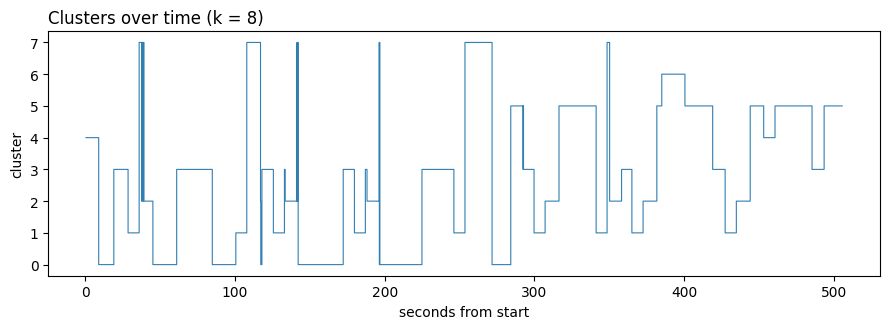

In [5]:
# chart: the cluster over time (plain; Part 4 overlays the rule-based events)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.step(model['ms'] / 1000, model['cluster'], where='post', lw=0.8, color='#2f7fb3')
ax.set_xlabel('seconds from start')
ax.set_ylabel('cluster')
ax.set_yticks(range(BEST_K))
ax.set_title(f'Clusters over time (k = {BEST_K})', loc='left')
plt.tight_layout()
plt.savefig(FIG_DIR + '/clusters_over_time.png', dpi=150)
plt.show()


**Done.** The scan, the episodes and the per-row labels are in `results/`.
Next: `part4_evaluation/04_evaluation.ipynb`.